# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

# cantidad de nulos para users

nulos_users = users.isnull()
print(nulos_users.sum())

print(nulos_users.mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
m_nulos = users['churn_date'].isnull()
users[~m_nulos]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
32,10032,Carlos,Lopez,44,MTY,2022-01-09 18:17:33.263315829,Premium,"1,71832E+18"
38,10038,Carlos,Torres,36,Medellín,2022-01-11 09:43:20.750187547,Premium,"1,7261E+18"
42,10042,Mateo,Gomez,56,Cali,2022-01-12 12:00:32.408102025,Basico,"1,72169E+18"
44,10044,Mateo,Garcia,58,Bogotá,2022-01-13 01:09:08.237059264,Basico,"1,7312E+18"
47,10047,Carlos,Ramirez,54,Bogotá,2022-01-13 20:52:01.980495123,Premium,"1,72843E+18"
...,...,...,...,...,...,...,...,...
3978,13978,Ana,Gomez,78,Bogotá,2024-12-25 05:59:43.795948992,Basico,"1,72264E+18"
3979,13979,Luis,Lopez,73,NaN,2024-12-25 12:34:01.710427616,Basico,"1,73508E+18"
3986,13986,Luis,Garcia,27,Medellín,2024-12-27 10:34:07.111777952,Premium,"1,72636E+18"
3993,13993,Carlos,Gomez,67,Cali,2024-12-29 08:34:12.513128288,Basico,"1,73172E+18"


In [12]:


# cantidad de nulos para usage
nulos_usage = usage.isnull()
print(nulos_usage.sum())

print(nulos_usage.mean())



id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Valores inválidos y sentinels — diagnóstico

**Columnas numéricas de `users`**

- **`user_id`**: secuencia consecutiva de 10000 a 13999, sin duplicados ni huecos.
  Al ser un identificador, sus estadísticos (media, desviación) no tienen
  interpretación posible.

- **`age`**: contiene el sentinel **`-999` en 55 registros (1.375%)**. Su impacto es
  desproporcionado respecto a su volumen: distorsiona la media llevándola de ~47 a
  33.74 años y dispara la desviación estándar a 123 años, un valor imposible en una
  variable acotada entre 0 y 79. Acción: imputar con la mediana (paso 3.1).

**Columnas numéricas de `usage`**

- **`id`**: secuencia consecutiva de 1 a 40,000, sin duplicados. Igual que
  `user_id`, no es interpretable estadísticamente.

- **`user_id`**: rango de 10000 a 13999, idéntico al de `users`, por lo que no hay
  eventos asociados a usuarios inexistentes. Sin embargo, solo **3,999 de los 4,000
  usuarios** registraron actividad: hay un cliente sin ninguna llamada ni mensaje.
  Esto obliga a usar un `left join` desde `users` en el paso 4.1, ya que un `inner
  join` lo eliminaría sin aviso.

- **`duration`**: no presenta valores negativos. Hay **15 registros con valor 0
  (0.08% de las llamadas)**, que corresponden a llamadas perdidas o no contestadas:
  son eventos válidos, no errores. La distribución está sesgada a la derecha (media
  5.20 vs. mediana 3.50) y el máximo es exactamente **120.00**, un valor
  sospechosamente redondo que podría indicar un tope del sistema más que una llamada
  real. Acción: conservar.

- **`length`**: no presenta valores negativos. Hay **133 registros con valor 0 (0.6%
  de los mensajes)**, lo cual sí es anómalo: un mensaje sin caracteres no debería
  registrarse. A diferencia del cero en `duration`, aquí el valor no tiene
  interpretación de negocio y probablemente funciona como sentinel o refleja una
  falla de captura. El máximo es **1,490 caracteres**, muy alejado del tercer cuartil
  (64) y equivalente a casi diez SMS estándar. Acción: conservar por su bajo impacto
  (0.6%) y documentar la anomalía.

**Inconsistencia estructural detectada**

Los valores presentes en `duration` (17,924) y `length` (22,104) suman **40,028**
sobre un total de 40,000 filas. El exceso de **28 registros** corresponde a eventos
que tienen ambos campos llenos simultáneamente, lo cual contradice el modelo de
datos: un evento es una llamada o un mensaje, nunca ambos. Acción: aislar y revisar
en el paso 3.2.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:

# explorar columnas numéricas de users
users[['user_id','age']].describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [14]:

anos_inexistentes = users['age'] == -999
anos_inexistentes.sum()


55

- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` 
Encontre en age minmo como -999 es un error

In [15]:
usage['user_id'].nunique()

3999

In [16]:
usage[['id','user_id','duration','length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [17]:
# Zero-value records in usage
(usage['duration'] == 0).sum()

15

In [18]:
(usage['length'] == 0).sum()

133

In [19]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']]
columnas_user.describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` cuenta con 3531 en ves 4000 filas, vemos que unique son 7 y el top es Bogotá, con una freq de 808
- La columna `plan` esta completa en count, solo tiene 2 unique, su top es básico y su freq es de 2595

In [20]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` ... cuenta completo, con 2 unicos, su top es texto y su frecuenca es 22092


In [21]:
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

In [22]:
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


---

✍️
 **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

**Valores inválidos o sentinels**

- **¿En qué columnas encontraste valores inválidos o sentinels?**
  En cuatro: `age` (sentinel `-999`, 55 registros), `city` (sentinel `"?"`, 96
  registros), `length` (133 ceros sin interpretación posible) y `duration` (15
  ceros, que en este caso sí son válidos). Adicionalmente se detectó una
  inconsistencia estructural en 28 filas de `usage` con `duration` y `length`
  llenos simultáneamente.

- **¿Qué acción tomarías?**
  Imputar `age` con la mediana; convertir el `"?"` de `city` a nulo para unificar
  ambos tipos de ausencia; conservar los ceros de `duration` por ser llamadas
  perdidas reales; conservar y documentar los ceros de `length` dado su bajo
  impacto (0.6%); y aislar las 28 filas contradictorias para revisión en el paso 3.2.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [23]:



# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors='coerce')
users['reg_date']

0      2022-01-01 00:00:00.000000000
1      2022-01-01 06:34:17.914478619
2      2022-01-01 13:08:35.828957239
3      2022-01-01 19:42:53.743435858
4      2022-01-02 02:17:11.657914478
                    ...             
3995   2024-12-29 21:42:48.342085520
3996   2024-12-30 04:17:06.256564144
3997   2024-12-30 10:51:24.171042768
3998   2024-12-30 17:25:42.085521392
3999   2024-12-31 00:00:00.000000000
Name: reg_date, Length: 4000, dtype: datetime64[ns]

In [24]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')
usage['date']

0       2024-01-01 00:00:00.000000000
1       2024-01-01 00:06:30.969774244
2       2024-01-01 00:13:01.939548488
3       2024-01-01 00:19:32.909322733
4       2024-01-01 00:26:03.879096977
                     ...             
39995   2024-06-29 23:33:56.120903022
39996   2024-06-29 23:40:27.090677266
39997   2024-06-29 23:46:58.060451510
39998   2024-06-29 23:53:29.030225754
39999   2024-06-30 00:00:00.000000000
Name: date, Length: 40000, dtype: datetime64[ns]

In [25]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves. Se estan poniendo años futuos inexistentes que son del 2026

In [26]:
anos_2026 = users['reg_date'].dt.year == 2026
anos_2026.sum()

40

In [27]:

# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()


array([2024.,   nan])

In [28]:
# --- Cambianod dhurndate a datatime ---

#Identifique que era un string
users['churn_date'] = users['churn_date'].str.replace(',', '.', regex=False)

# se convirtio a numero
users['churn_date'] = pd.to_numeric(users['churn_date'], errors='coerce')

# Se convirtio en tiempo
users['churn_date'] = pd.to_datetime(users['churn_date'], unit='ns')

# Validacion que se intercambieron 466 no nulos a data
print("Non-null churn dates:", users['churn_date'].notna().sum())
print(users['churn_date'].describe())

Non-null churn dates: 466
count                     466
unique                    197
top       2024-07-30 22:53:20
freq                        6
first     2024-06-01 00:00:00
last      2024-12-30 23:06:40
Name: churn_date, dtype: object


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

### 2.3 Fechas fuera de rango — diagnóstico

**¿Aparecen años imposibles?**

Sí, en una de las tres columnas de fecha. Además se detectó un problema de formato
que impedía evaluar una segunda columna.

- **`reg_date` (users)**: los años presentes son 2022, 2023, 2024 y **2026**. Dado
  que el dataset contiene información registrada hasta 2024, las fechas de 2026
  corresponden a registros con **dos años de anticipación**: clientes que figuran
  como dados de alta en un momento que aún no ocurre. Afecta a **40 registros
  (1.00%)**.
  Llama la atención que **no aparece ningún 2025**. Si se tratara de corrupción
  aleatoria, esperaríamos años dispersos (2025, 2027, 2031). Que los 40 errores
  caigan exactamente en el mismo año apunta a una **falla sistemática de captura o
  a un desplazamiento en la carga de datos**, no a errores individuales.

- **`date` (usage)**: el único año presente es **2024**, consistente con el periodo
  declarado del análisis. No hay fechas fuera de rango. La columna conserva sus 50
  valores nulos, correctamente preservados como `NaT` tras la conversión.

- **`churn_date` (users)**: no presentaba años imposibles, pero **no era legible
  como fecha**. La columna venía almacenada como texto en notación científica con
  coma decimal (`"1,71832E+18"`), producto de una exportación con configuración
  regional en español, y su contenido real era un timestamp Unix en nanosegundos.
  Fue necesario un proceso de tres pasos —sustituir la coma por punto, convertir a
  numérico y luego a fecha— antes de poder validarla.
  Una vez corregida, arroja **466 cancelaciones (11.65% de la base)**, todas
  comprendidas entre el **1 de junio y el 30 de diciembre de 2024**. No se detectan
  bajas anteriores a su propio registro ni posteriores al periodo de análisis.
  La columna presenta solo **197 valores únicos para 466 registros**, consecuencia
  de la pérdida de precisión de la notación científica, que conserva 6 cifras
  significativas de un número de 19 dígitos: la fecha se mantiene correcta, pero la
  hora exacta quedó redondeada.

**¿Qué harías con ellas?**

- **`reg_date` = 2026 → marcar como nulo (`pd.NA`).** No procede eliminar las 40
  filas: esos usuarios tienen edad, ciudad, plan y consumo válidos, y descartarlos
  significaría perder información de negocio por un solo campo corrupto. Tampoco
  procede imputar una fecha, ya que cualquier valor asignado sería inventado y
  contaminaría el cálculo de antigüedad del cliente. Marcarlos como nulo preserva al
  usuario y deja constancia explícita de que su fecha de alta se desconoce.

- **`date` (usage) → ninguna acción.** No presenta años imposibles.

- **`churn_date` → conservar tras la corrección de formato.** La pérdida de
  precisión horaria no requiere tratamiento adicional: el análisis de churn se
  realiza a nivel de cliente y de mes, no de hora, por lo que el impacto es nulo.

**Hallazgo de negocio.** La totalidad de las cancelaciones se concentra en el
segundo semestre de 2024, sin un solo registro de baja en 2022, 2023 ni el primer
semestre de 2024. Esto sugiere que el registro de cancelaciones comenzó a operar en
junio de 2024 o que existió un evento concreto que detonó la fuga. En consecuencia,
el 11.65% no debe leerse como una tasa de abandono histórica, sino como una tasa
concentrada en siete meses.

**Impacto en el análisis.** Las fechas de registro no intervienen en el cálculo de
las métricas de uso del paso 4, que se agregan por usuario y no por periodo. Marcar
los 40 registros de 2026 como nulos **no afecta ningún resultado del análisis de
consumo**; únicamente impide calcular la antigüedad de ese 1% de clientes.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [29]:


# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace(-999,np.nan)

age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [30]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [31]:
# Marcar fechas futuras como NA para reg_date



anos_2026 = users['reg_date'].dt.year == 2026
users.loc[ anos_2026 , 'reg_date' ] = np.nan

# Verificar cambios
anos_2026.sum()


40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [32]:
# Verificación MAR en usage (Missing At Random) para duration
m_nulos_duration = usage['duration'].isnull()
verficacion_mar_durartion = pd.crosstab(usage['type'],m_nulos_duration)
verficacion_mar_durartion

duration,False,True
type,,
call,17908,0
text,16,22076


In [33]:
# Verificación MAR en usage (Missing At Random) para length
m_nulos_length = usage['length'].isnull()
verficacion_mar_length = pd.crosstab(usage['type'],m_nulos_length)
verficacion_mar_length

length,False,True
type,,
call,12,17896
text,22092,0


In [34]:
vista_usage = (~m_nulos_duration) & (~m_nulos_length)
usage[vista_usage].describe()

,id,user_id,duration,length
count,28.000000,28.000000,28.000000,28.000000
mean,20448.607143,12120.428571,69.277500,665.964286
std,12267.893333,1250.798869,59.649141,726.891937
min,1415.000000,10085.000000,0.400000,19.000000
25%,11246.500000,10958.750000,1.540000,46.250000
50%,22934.000000,12331.500000,120.000000,69.500000
75%,26734.000000,13170.500000,120.000000,1490.000000
max,39523.000000,13920.000000,120.000000,1490.000000


In [35]:
usage = usage[~vista_usage]
usage.describe()

,id,user_id,duration,length
count,39972.000000,39972.000000,17896.000000,22076.000000
mean,20000.186105,12002.323301,5.101985,51.348840
std,11546.786015,1157.224097,5.923969,45.651973
min,1.000000,10000.000000,0.000000,0.000000
25%,9999.750000,10996.000000,1.437500,37.000000
50%,19997.500000,12013.000000,3.500000,50.000000
75%,30002.250000,13004.250000,6.970000,64.000000
max,40000.000000,13999.000000,120.000000,1490.000000


### 3.2 Verificación MAR — diagnóstico

**Resultado de la verificación.** El cruce entre `type` y la ausencia de valores
confirma una dependencia total:

| | `duration` nula | `length` nula |
|---|---|---|
| `call` (17,908) | **0** | 17,896 |
| `text` (22,092) | 22,076 | **0** |

Ninguna llamada carece de duración y ningún mensaje carece de longitud. La ausencia
está determinada al 100% por el tipo de evento, no por azar.

**Precisión conceptual.** El enunciado plantea verificar si los nulos son MAR
(*Missing At Random*), es decir, si su ausencia depende de otra variable observada.
La condición se cumple —dependen de `type`—, pero el caso es en realidad más
estricto: se trata de **nulos estructurales**. No es que el dato se haya perdido y
su pérdida correlacione con el tipo de evento; es que el dato **no existe**. Un
mensaje no tiene duración que perder y una llamada no tiene caracteres que contar.
Acción: **dejarlos como nulos**, sin imputar ni eliminar filas.

**Registros contradictorios.** La misma tabla revela 16 mensajes con `duration`
registrada y 12 llamadas con `length` registrada. Al construir la máscara combinada
se confirma que corresponden a **28 filas únicas que tienen ambos campos llenos
simultáneamente** (0.07% de `usage`), lo cual contradice el modelo de datos.

El análisis de sus valores muestra que no se trata de un error aleatorio: la mediana
y el tercer cuartil de `duration` en estas filas son **exactamente 120.00**, y el
tercer cuartil de `length` es **exactamente 1,490**. Ambos coinciden con los valores
máximos de todo el dataset detectados en el paso 2.2. Es decir, **los supuestos
valores extremos de `duration` y `length` no reflejan comportamiento de usuarios,
sino el tope artificial escrito por estos 28 registros defectuosos.**

Acción: **eliminar las 28 filas antes de la agregación del paso 4.** Conservarlas
implicaría que el análisis de outliers del paso 5.2 marcara como comportamiento
extremo lo que en realidad es un fallo de registro, distorsionando tanto las métricas
de uso por usuario como las conclusiones comerciales derivadas de ellas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [36]:
# ============ 4.1 Aggregate usage per user ============

# Helper columns
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# One row per user
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [39]:
# Renombrar columnas

# observar resultado# Rename columns
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})


usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [40]:
# LEFT join from users: keeps the user with zero activity
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Users with no events get 0, not NaN
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

# Control check: must be 4000
print("Rows:", user_profile.shape[0])
user_profile.head(5)

Rows: 4000


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [41]:
# Resumen estadístico de las columnas numéricas
# ============ 4.2 Summary statistics ============
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.519000,4.474000,22.826283
std,17.689919,2.359138,2.143589,16.591590
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.087500
50%,48.000000,5.000000,4.000000,19.730000
75%,63.000000,7.000000,6.000000,31.182500
max,79.000000,17.000000,15.000000,155.690000


In [42]:
# Distribución porcentual del tipo de plan
# Plan distribution (%)
user_profile['plan'].value_counts(normalize=True) * 100



Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

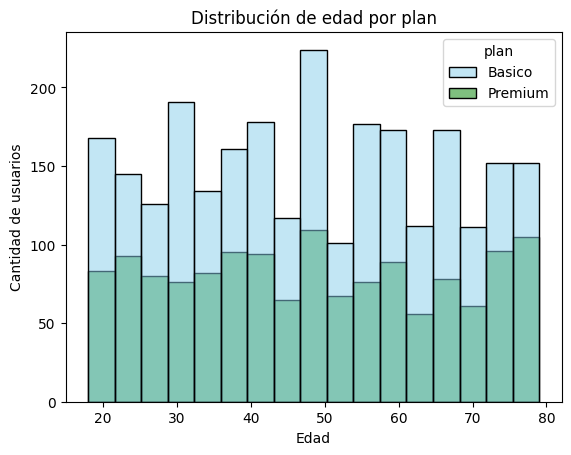

In [43]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución ...

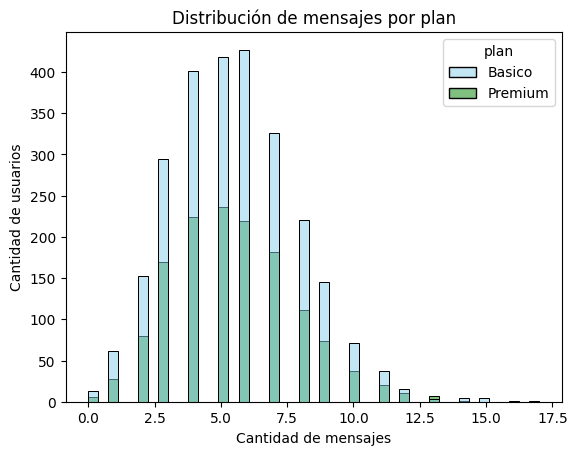

In [45]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- ....

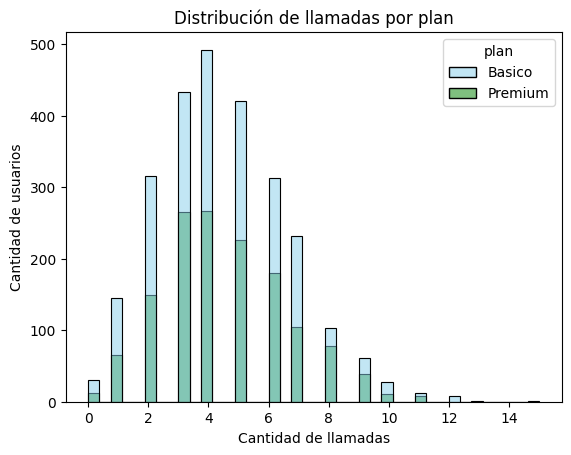

In [46]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución ...

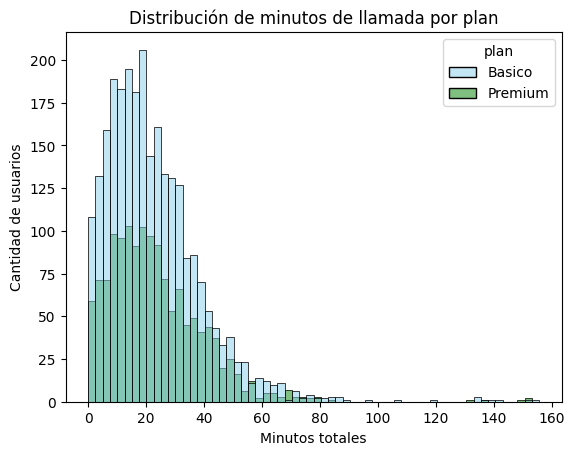

In [47]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos totales')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

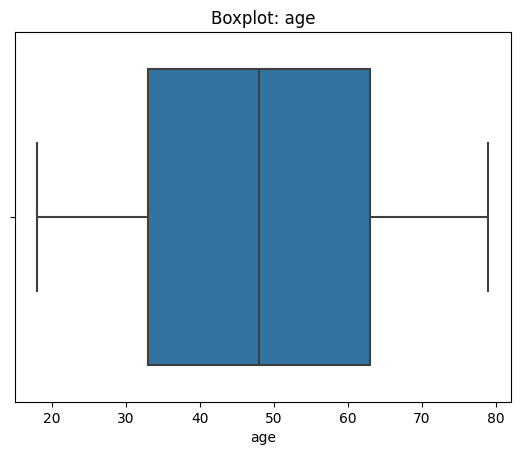

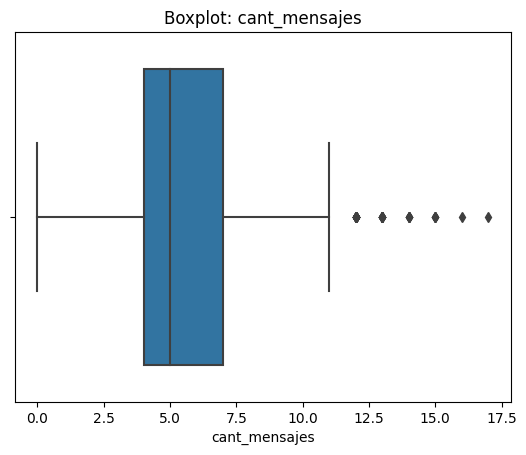

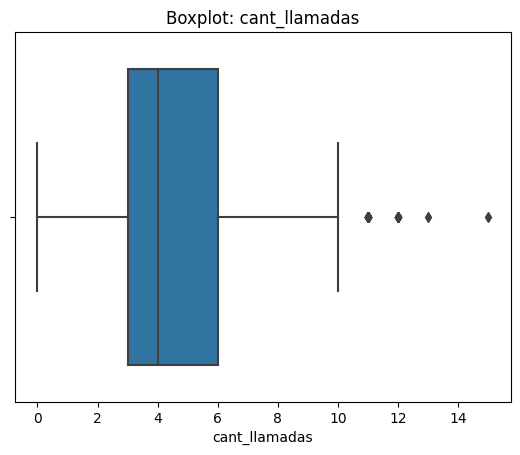

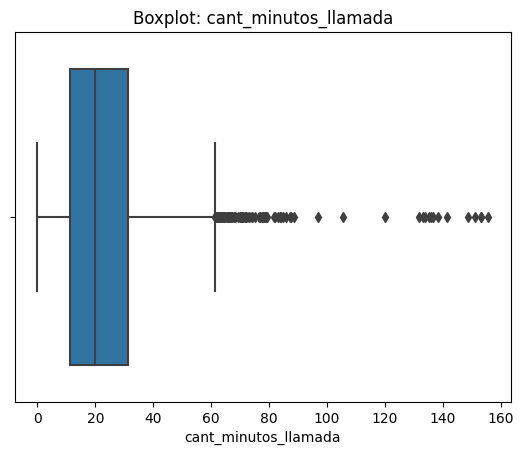

In [48]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [49]:
# Calcular límites con el método IQR

columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q1 + 1.5 * iqr + iqr  # upper fence
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: límite superior = {limite_superior:.2f} | outliers = {n_outliers}")


cant_mensajes: límite superior = 11.50 | outliers = 46
cant_llamadas: límite superior = 10.50 | outliers = 30
cant_minutos_llamada: límite superior = 61.32 | outliers = 96


In [51]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.519000,4.474000,22.826283
std,2.359138,2.143589,16.591590
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.730000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


💡 Insights:

- **`cant_mensajes`**: 46 usuarios (1.15%) superan el límite superior de 11.50
  mensajes. El máximo observado es 17, apenas 1.5 veces el límite y 3.4 veces la
  mediana (5). Son valores perfectamente plausibles para un cliente activo, no
  errores de registro. **Mantener**: eliminarlos descartaría justamente a los
  usuarios de mayor consumo, que son los más relevantes para decisiones de oferta
  comercial.

- **`cant_llamadas`**: 30 usuarios (0.75%) superan el límite de 10.50 llamadas, con
  un máximo de 15. La distancia al límite es aún menor que en mensajes y el rango
  total de la variable es estrecho (0 a 15). **Mantener**: no hay ningún valor
  físicamente imposible ni indicio de error; se trata de variación natural de uso.

- **`cant_minutos_llamada`**: 96 usuarios (2.4%) superan el límite de 61.32 minutos,
  con un máximo de 155.69. Es la variable con mayor dispersión relativa y la que
  muestra un sesgo más pronunciado a la derecha (media 22.83 vs. mediana 19.73).
  **Mantener**: estos usuarios no representan un defecto de datos sino el segmento
  de consumo intensivo. Son, de hecho, el hallazgo comercial más accionable del
  análisis, ya que concentran el riesgo de exceder los minutos incluidos en su plan.

**Criterio general.** El método IQR identifica valores estadísticamente alejados de
la masa de datos, pero no distingue entre error y comportamiento legítimo. En las
tres variables los máximos son coherentes con el uso real de un servicio móvil y se
sitúan dentro de rangos plausibles, por lo que se conservan todos los registros. Los
únicos valores que sí correspondían a un defecto —las 28 filas con `duration` y
`length` simultáneos— ya fueron eliminados en el paso 3.2, antes de construir estas
métricas agregadas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [52]:
# Crear columna grupo_uso
condiciones_uso = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
etiquetas_uso = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones_uso, etiquetas_uso, default='Alto uso')
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      781
Alto uso      276
Name: grupo_uso, dtype: int64

In [53]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [54]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
etiquetas_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, etiquetas_edad, default='Adulto Mayor')
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [55]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

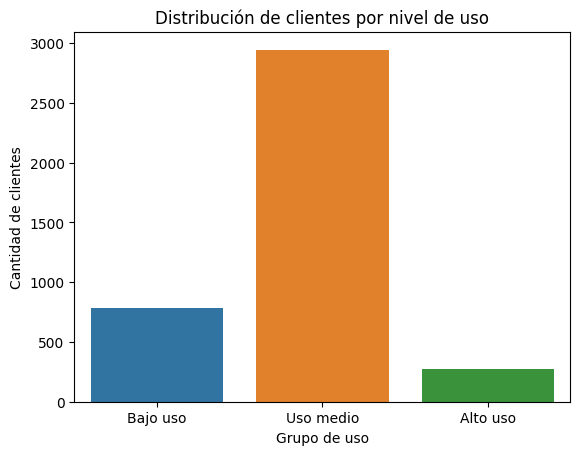

In [56]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso','Uso medio','Alto uso'])
plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

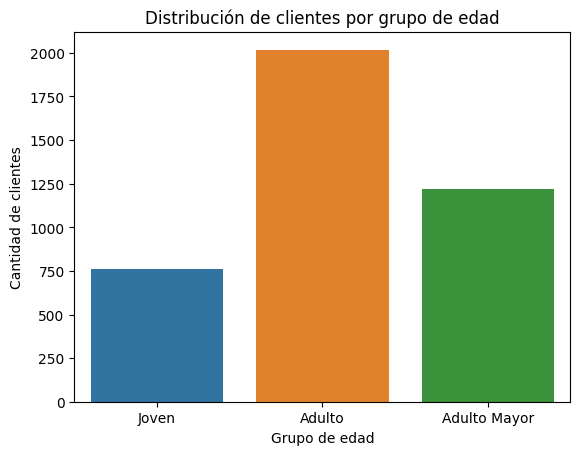

In [57]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven','Adulto','Adulto Mayor'])
plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- **`churn_date` (88.35%, 3,534 de 4,000 registros)**: el porcentaje de vacíos
  sugería descartar la columna, pero el vacío significaba "cliente activo". Los 466
  registros restantes revelaron una **tasa de abandono del 11.65%**, el hallazgo de
  negocio más relevante del dataset. Además venía almacenada como texto en notación
  científica con coma decimal (`"1,71832E+18"`), ilegible como fecha sin un proceso
  de limpieza de tres pasos.
- **`city` (14.13%, 565 registros)**: 469 nulos declarados más **96 ocurrencias del
  sentinel `"?"`**, invisible para el conteo de nulos. La proporción real de clientes
  sin ciudad era un 20% mayor a la reportada inicialmente.
- **`age` (1.38%, 55 registros)**: el sentinel `-999` distorsionaba la edad promedio
  de ~47 a **33.74 años** y disparaba la desviación estándar a **123 años**, un valor
  imposible en una variable acotada a 79. Imputado con la mediana.
- **`reg_date` (1.00%, 40 registros)**: fechas de alta en 2026, dos años en el
  futuro. La ausencia de cualquier 2025 indica una falla sistemática de captura, no
  errores individuales. Marcados como nulos.
- **`usage` (0.07%, 28 registros)**: eventos con `duration` y `length` llenos
  simultáneamente, contradiciendo el modelo de datos. Sus valores estaban saturados
  en los topes del rango. Eliminados antes de la agregación; su remoción redujo la
  desviación estándar de `length` en 19%.
- **Nulos conservados deliberadamente**: el 55.19% de `duration` y el 44.74% de
  `length` son **nulos estructurales** —un mensaje no tiene duración, una llamada no
  tiene caracteres—. Imputarlos habría fabricado consumo inexistente.

🔍 **Segmentos por Edad**

- La base se concentra en **Adultos de 30 a 59 años (2,018 clientes, 50.5%)**,
  seguida de **Adultos Mayores de 60+ (1,222, 30.6%)** y **Jóvenes menores de 30
  (760, 19.0%)**.
- El histograma de edad muestra una **distribución prácticamente uniforme** entre
  los 18 y los 79 años, sin concentración en ningún rango etario. El boxplot no
  detecta un solo valor atípico.
- **No se observa relación entre edad y tipo de plan**: la proporción de Premium se
  mantiene estable a lo largo de todo el rango de edad. La edad, por sí sola, **no
  es un criterio útil de segmentación comercial** en esta base.

📊 **Segmentos por Nivel de Uso**

- **Uso medio: 2,943 clientes (73.6%)** — el grueso absoluto de la base.
- **Bajo uso: 781 clientes (19.5%)** — menos de 5 llamadas y 5 mensajes.
- **Alto uso: 276 clientes (6.9%)** — el segmento de consumo intensivo.
- Las tres variables de consumo presentan **sesgo a la derecha**: en minutos de
  llamada la media (22.83) supera a la mediana (19.73) y el máximo alcanza 155.69,
  casi 8 veces la mediana.
- El reparto Básico/Premium es de **64.9% / 35.1%**, pero los histogramas muestran
  que **ambos planes consumen prácticamente lo mismo**: las distribuciones de
  mensajes, llamadas y minutos se superponen casi por completo. El plan contratado
  no predice el comportamiento de uso.

➡️ **Esto sugiere que** la segmentación comercial actual de ConnectaTel no responde
al comportamiento real de sus clientes. Ni la edad ni el plan contratado explican
las diferencias de consumo: el único eje con poder discriminante es el volumen de
uso efectivo. Más grave aún, **la oferta está severamente sobredimensionada**. El
plan Básico incluye 100 minutos y el Premium 600, pero el consumo máximo de toda la
base es de **155.69 minutos** y la mediana apenas alcanza los **19.73 minutos**: el
cliente promedio utiliza menos del 20% de los minutos del plan más barato, y ningún
cliente se acerca siquiera a un cuarto del Premium. Los 1,405 clientes que pagan
$25 mensuales por el Premium están financiando una capacidad que nunca usan, lo que
ayuda a explicar la fuga del 11.65% concentrada en el segundo semestre de 2024.

💡 **Recomendaciones**

1. **Rediseñar la escala de planes a la baja.** Con un consumo máximo de 156 minutos,
   los 600 minutos del Premium carecen de justificación. Se propone un plan de
   entrada de ~30 minutos que cubra al 75% de la base (Q3 = 31.18 min) y un plan
   superior de ~160 minutos que absorba al 100% del consumo observado, a un precio
   intermedio entre los $12 y $25 actuales.
2. **Migrar a los 781 clientes de Bajo uso a una tarifa reducida.** Pagan por un
   servicio que apenas utilizan y son los candidatos naturales a cancelar. Una
   tarifa ajustada a su consumo real protege ingreso recurrente que hoy está en
   riesgo.
3. **Atender a los 276 clientes de Alto uso como segmento prioritario.** Son el 6.9%
   que concentra el consumo real. Convienen beneficios de retención antes que
   restricciones: son los únicos que podrían acercarse a los límites del plan.
4. **Auditar la relación entre Premium y consumo.** Si un tercio de la base paga el
   doble sin consumir más, el diferencial de precio no está sustentado en valor
   entregado. Revisar qué atributos no medidos en este dataset (datos móviles,
   cobertura, atención) justifican la brecha, o corregir el precio.
5. **Investigar el origen de las cancelaciones.** Las 466 bajas se concentran
   íntegramente entre junio y diciembre de 2024, sin un solo registro previo. Debe
   determinarse si responde a un evento comercial concreto o al inicio del registro
   de cancelaciones, ya que condiciona la lectura de la tasa de abandono.
6. **Corregir el origen de los datos.** Los sentinels (`-999`, `"?"`), el formato de
   `churn_date` y las fechas de 2026 son fallas del sistema de captura, no del
   análisis. Estandarizar la exportación evitaría repetir esta limpieza en cada ciclo
   y reduciría el riesgo de decisiones basadas en una edad promedio 13 años menor a
   la real.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`